In [31]:
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv('/home/tahachoksi/GitHub/INM430-PrinciplesOfDataScience-main/dataset/dataset.csv')

In [21]:
print(df.head(10))

  Country Name Country Code  \
0    Australia          AUS   
1    Indonesia          IDN   
2        India          IND   
3        Japan          JPN   
4  Korea, Rep.          KOR   
5     Malaysia          MYS   
6      Myanmar          MMR   
7  New Zealand          NZL   
8  Philippines          PHL   
9    Singapore          SGP   

  Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]  \
0                                            213.702                                     
1                                            170.412                                     
2                                            247.968                                     
3                                            124.237                                     
4                                            113.027                                     
5                                            117.027                                     
6                           

In [23]:
df['Educational attainment, at least completed upper secondary, population 25+, total (%) (cumulative) [SE.SEC.CUAT.UP.ZS]'] = pd.to_numeric(df['Educational attainment, at least completed upper secondary, population 25+, total (%) (cumulative) [SE.SEC.CUAT.UP.ZS]'].replace('..', pd.NA), errors='coerce')


In [27]:
df['Government expenditure on education, total (% of government expenditure) [SE.XPD.TOTL.GB.ZS]'] = pd.to_numeric(df['Government expenditure on education, total (% of government expenditure) [SE.XPD.TOTL.GB.ZS]'].replace('..',pd.NA), errors='coerce')

In [51]:
geojson_file = '/home/tahachoksi/GitHub/INM430-PrinciplesOfDataScience-main/map.geo.json'
world = gpd.read_file(geojson_file)

df_country = df[['Country Name', 'Government expenditure on education, total (% of government expenditure) [SE.XPD.TOTL.GB.ZS]', 'Educational attainment, at least completed upper secondary, population 25+, total (%) (cumulative) [SE.SEC.CUAT.UP.ZS]']]

world_data = world.merge(df_country, left_on='name', right_on='Country Name', how='left')

<Figure size 2100x1500 with 0 Axes>

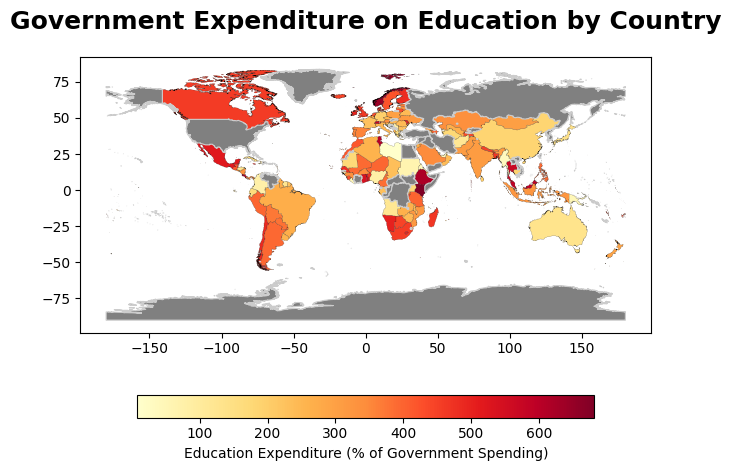

In [ ]:
# Plot the heatmap for Government Expenditure on Education
plt.figure(figsize=(14, 10), dpi=150)

# Create a mask for countries with missing data (NaN values)
world_data['missing_data'] = world_data['Government expenditure on education, total (% of government expenditure) [SE.XPD.TOTL.GB.ZS]'].isna()

# Plot with enhanced styling
ax = world_data.plot(column='Government expenditure on education, total (% of government expenditure) [SE.XPD.TOTL.GB.ZS]',
                     cmap='YlOrRd', linewidth=0.1, edgecolor='0.0', legend=True, legend_kwds={'label': "Education Expenditure (% of Government Spending)", 'orientation': "horizontal", 'shrink': 0.8})

# Assign black color to countries with missing data
world_data[world_data['missing_data']].plot(ax=ax, color='grey', edgecolor='0.8', linewidth=0.8)

# Add title
plt.title('Government Expenditure on Education by Country', fontsize=18, weight='bold', pad=20)

# Make layout tight
plt.tight_layout()
plt.show()


In [72]:
# Create a DataFrame with country names and their educational attainment data
heatmap_data = world_data[['Country Name', 'Educational attainment, at least completed upper secondary, population 25+, total (%) (cumulative) [SE.SEC.CUAT.UP.ZS]']]

# Set the country as the index
heatmap_data = heatmap_data.set_index('Country Name')

# Replace NaN values with None (or a placeholder like -1 or 0 if preferred)
heatmap_data = heatmap_data.applymap(lambda x: None if pd.isna(x) else x)

# Plotting the heatmap
plt.figure(figsize=(12, 8))

# Use sns.heatmap to plot the heatmap
sns.heatmap(heatmap_data.T, annot=True, cmap='YlOrRd', cbar_kws={'label': 'Educational Attainment (%)'}, linewidths=0.5,
            mask=heatmap_data.isna(), cbar=False)  # mask NaN values to hide them

# Title and labels
plt.title('Educational Attainment (Completed Upper Secondary) by Country', fontsize=20, weight='bold')
plt.xlabel('Countries', fontsize=14)
plt.ylabel('Percentage (%)', fontsize=14)

# Rotate the x labels for better readability
plt.xticks(rotation=90)

# Show the plot
plt.tight_layout()
plt.show()


/tmp/ipykernel_440/1949619166.py:8: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  heatmap_data = heatmap_data.applymap(lambda x: None if pd.isna(x) else x)


IndexError: Inconsistent shape between the condition and the input (got (259, 259) and (1, 258))

<Figure size 1200x800 with 0 Axes>